# Distributional prediction shootout

This benchmark compares 21 distributional regression procedures across 16 planted-truth settings (eight conditional distributions at 500 and 5,000 training rows, three seeds each) and all 35 regression datasets of the OpenML-CTR23 suite (three splits each). Every arm receives raw responses on their natural scale and predicts 99 conditional quantiles (0.01 to 0.99) for every test row; every arm is scored with the same quantile-based continuous ranked probability score (CRPS), calibration error, interval coverage, and — for parametric arms — negative log likelihood.

**Bottom line.** On planted distributions, mboostrs holds the top five ranks overall (`LSS_select_noncyclic` 5.25, `mb.fit` with `lss_trees=True` 5.34, default `mb.fit` 5.41, `LSS_select` 6.25, and `mboostrs.quantiles` 6.44), ahead of tuned hessboost (7.75), drforest (8.75–9.19), and DisTreebution CRPS forests (9.09). On the planted interaction task (`S7_interaction` at 5,000 rows), `mb.fit` cuts excess CRPS over the true distribution to 4.2% (1.5% with `lss_trees=True`), ahead of tuned hessboost (7.7%), CRPS forest (7.9%), and LightGBM quantiles (8.0%). On real OpenML-CTR23 datasets, tree ensembles still lead on CRPS (LightGBM quantiles rank 3.48, QRF 5.16, tuned CRPS forest 5.77, tuned hessboost 6.13, CatBoost 7.26 vs. `mboostrs.quantiles` 10.19, `mb.fit` 11.39, and `LSS_select_tree` 11.45), while mboostrs delivers the lowest real-data quantile calibration error (`mboostrs.quantiles` 0.024, `LSS_select_noncyclic` 0.028, 90% coverage 0.90–0.91).

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | Full conditional predictive distributions on raw-unit continuous responses |
| **Primary score** | Continuous ranked probability score (CRPS) computed identically from 99 predicted quantiles (0.01, …, 0.99); lower is better |
| **Secondary scores** | Mean absolute quantile calibration error over the 99 levels, central 50%/90%/98% coverage and 90% width/SD, parametric log score (NLL), and single-thread wall-clock seconds |
| **Task suites** | 16 planted-truth settings (8 generators × 2 sample sizes × 3 seeds = 48 runs/arm) and 35 OpenML-CTR23 regression datasets (3 splits = 105 runs/arm) |
| **Paired uncertainty** | Geometric-mean CRPS ratios across tasks with 10,000-draw task-level bootstrap 95% intervals; ±1% tie band |
| **Exposure note** | Several library changes were developed with the earlier benchmark results in view on seed-0 data of a subset of tasks; these scores are therefore not an independent test of those changes |
:::

In [1]:
import json
import sys
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "Cargo.toml").exists())
sys.path.insert(0, str(ROOT))
from docs.book.cases.bench_tables import table

STUDY = Path("distributional_shootout") if Path("distributional_shootout/analysis.json").exists() else ROOT / "docs/benchmarks/distributional_shootout/v2"
analysis = json.loads((STUDY / "analysis.json").read_text())
checks = json.loads((STUDY / "v2_comparison.json").read_text())
synth, real = analysis["synth"], analysis["real"]

NAMES = {
    "mboostrs.LSS_select": "mboostrs LSS_select",
    "mboostrs.LSS_select_noncyclic": "mboostrs LSS_select, non-cyclic",
    "mboostrs.LSS_select_tree": "mboostrs LSS_select + trees",
    "mboostrs.GaussianLSS": "mboostrs GaussianLSS",
    "mboostrs.fit": "mboostrs mb.fit",
    "mboostrs.fit_lss_trees": "mboostrs mb.fit, lss_trees=True",
    "mboostrs.quantiles": "mboostrs quantiles",
    "hessboost.tuned": "hessboost, tuned",
    "hessboost.normal": "hessboost normal, defaults",
    "ngboost.normal": "NGBoost normal",
    "catboost.uncertainty": "CatBoost RMSEWithUncertainty",
    "lightgbm.quantiles": "LightGBM quantiles",
    "qrf": "quantile regression forest",
    "drforest.tuned": "drforest, tuned",
    "drforest.mmd": "drforest MMD",
    "drforest.cart": "drforest CART",
    "distreebution.crps_rf_tuned": "CRPS forest, tuned",
    "distreebution.crps_rf": "CRPS forest",
    "distreebution.pmqrf": "pinball multi-quantile forest",
    "reference.gaussian_linear": "least squares, constant SD",
    "reference.climatology": "climatology",
}
name = lambda arm: NAMES.get(arm, arm)


def ranks(block):
    rows = [{"method": name(a), "mean_rank": r, "skill": block["skill_over_climatology"][a]["mean"],
             "gap": 100 * block["gap_to_best"][a]["median"], "best": block["gap_to_best"][a]["best_count"]}
            for a, r in block["mean_rank"].items() if r is not None]
    return pl.DataFrame(rows).sort("mean_rank")

## Compared procedures

The study evaluates seven mboostrs arms alongside fourteen external distributional and reference arms:

- **mboostrs arms:** `LSS_select` (cyclic family selection over Gaussian, Student-t, Gamma, and LogNormal LSS with automatic `response_scale="auto"`), `LSS_select_noncyclic` (non-cyclic `tune_mstop` over the same families), `LSS_select_tree` (adding a depth-6 joint tree to every parameter), `GaussianLSS` (single family), `mb.fit` (automatic specification search with default `na_action="impute"`, `unseen_levels="average"`, guarded interaction adoption, and `residual_tree="auto"`), `mb.fit` with `lss_trees=True`, and `mboostrs.quantiles` (quantile boosting across levels with `qoffset=tau`, `nu=0.3`, and `response_scale="auto"`).
- **External boosting arms:** `hessboost` (default normal and tuned family/depth/rate grid), `NGBoost` (normal), `CatBoost` (`RMSEWithUncertainty`), and `LightGBM` (quantile regression).
- **Distributional forest arms:** quantile regression forest (`qrf`), `drforest` (CART, MMD, and tuned), and `DisTreebution` (`crps_rf`, tuned `crps_rf`, and `pmqrf`).
- **References:** constant-SD ordinary least squares (`reference.gaussian_linear`) and unconditional empirical quantiles (`reference.climatology`).

## Planted-truth distributions

Across all 16 planted settings (8 generating processes at 500 and 5,000 training rows), the five leading arms are all mboostrs procedures. `mboostrs.LSS_select_noncyclic` takes first place by mean rank (5.25, median gap to best 0.2%), followed closely by `mb.fit` with `lss_trees=True` (5.34, 5 settings won), default `mb.fit` (5.41, highest mean skill over climatology at 0.381), `LSS_select` (6.25), and `mboostrs.quantiles` (6.44).

In [2]:
display(table(
    ranks(synth), title="Planted distributions: CRPS ranks",
    subtitle=f"{synth['rank_tasks']} task settings (8 generators at 500 and 5,000 rows), "
             "mean over 3 seeds; lower rank is better",
    labels={"mean_rank": "mean rank", "skill": "skill over climatology", "gap": "median gap to best (%)",
            "best": "settings won"},
    better={"mean_rank": "min", "skill": "max", "gap": "min"}, formats={"mean_rank": 2, "gap": 1},
    notes=["Rank 1 is the lowest CRPS on a task setting. Skill is 1 − CRPS / CRPS(climatology), "
           "averaged over settings; the gap is CRPS over the best arm's CRPS, minus 1."],
))

GT(_tbl_data=shape: (21, 5)
┌─────────────────────────────────┬───────────┬───────────┬───────────┬──────┐
│ method                          ┆ mean_rank ┆ skill     ┆ gap       ┆ best │
│ ---                             ┆ ---       ┆ ---       ┆ ---       ┆ ---  │
│ str                             ┆ f64       ┆ f64       ┆ f64       ┆ i64  │
╞═════════════════════════════════╪═══════════╪═══════════╪═══════════╪══════╡
│ mboostrs LSS_select, non-cycli… ┆ 5.25      ┆ 0.360061  ┆ 0.173627  ┆ 2    │
│ mboostrs mb.fit, lss_trees=Tru… ┆ 5.34375   ┆ 0.377564  ┆ 0.601606  ┆ 5    │
│ mboostrs mb.fit                 ┆ 5.40625   ┆ 0.38067   ┆ 1.003835  ┆ 3    │
│ mboostrs LSS_select             ┆ 6.25      ┆ 0.359639  ┆ 0.480426  ┆ 3    │
│ mboostrs quantiles              ┆ 6.4375    ┆ 0.363425  ┆ 1.240087  ┆ 4    │
│ …                               ┆ …         ┆ …         ┆ …         ┆ …    │
│ quantile regression forest      ┆ 14.625    ┆ 0.347985  ┆ 7.538181  ┆ 0    │
│ least squares, constant SD      ┆ 16.0625   ┆ 0.302543  ┆ 13.181591 ┆ 0    │
│ mboostrs LSS_select + trees     ┆ 17.6875   ┆ 0.319486  ┆ 11.766016 ┆ 0    │
│ hessboost normal, defaults      ┆ 18.75     ┆ -2.1114e7 ┆ 20.367007 ┆ 0    │
│ climatology                     ┆ 20.6875   ┆ 0.0       ┆ 70.393529 ┆ 0    │
└─────────────────────────────────┴───────────┴───────────┴───────────┴──────┘, _body=<great_tables._gt_data.Body object at 0x109d693a0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='mean_rank', type=<ColInfoTypeEnum.default: 1>, column_label='mean rank', column_align='right', column_width=None, stub_level=None), ColInfo(var='skill', type=<ColInfoTypeEnum.default: 1>, column_label='skill over climatology', column_align='right', column_width=None, stub_level=None), ColInfo(var='gap', type=<ColInfoTypeEnum.default: 1>, column_label='median gap to best (%)', column_align='right', column_width=None, stub_level=None), ColInfo(var='best', type=<ColInfoTypeEnum.default: 1>, column_label='settings won', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10a332ed0>, _spanners=Spanners([]), _heading=Heading(title='Planted distributions: CRPS ranks', subtitle='16 task settings (8 generators at 500 and 5,000 rows), mean over 3 seeds; lower rank is better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x109713b90>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x109713f20>, _source_notes=["Rank 1 is the lowest CRPS on a task setting. Skill is 1 − CRPS / CRPS(climatology), averaged over settings; the gap is CRPS over the best arm's CRPS, minus 1."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1099CC110>, mask=None), grpname=None, colname='mean_rank', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1099CC110>, mask=None), grpname=None, colname='mean_rank', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1099CC110>, mask=None), grpname=None, colname='mean_rank', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1099CC110>, mask=None), grpname=None, colname='mean_rank', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1099CC110>, mask=None), grpname=None, colname='mean_rank', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1099CC110>, 

### Excess CRPS by generating process

Grouping by data-generating structure explains the rankings:

- **Additive parametric truths (`S1`, `S2`, `S3`, `S4`, `S8`):** `LSS_select`, `LSS_select_noncyclic`, and `mb.fit` sit within 0.0–2.5% of the true conditional distribution at 5,000 rows, outperforming every forest and tree ensemble.
- **Bimodal and shape-shifting truths (`S5`, `S6`):** nonparametric quantile boosting (`mboostrs.quantiles`) matches or beats every forest (1.1% excess on `S5`, 0.4% on `S6`), whereas single-mode parametric arms incur 10–14% excess on the bimodal mixture.
- **Pure interaction in mean and spread (`S7`):** guarded interaction adoption and residual trees bring `mb.fit` to 4.2% excess CRPS (and `mb.fit` with `lss_trees=True` to 1.5%, best of all 21 arms), while purely additive `LSS_select` stays at 57.2%.

In [3]:
GENERATORS = {"S1": "Gaussian, spread varies", "S2": "Student t, 3 df", "S3": "gamma",
              "S4": "log-normal", "S5": "bimodal", "S6": "shape varies", "S7": "x0·x1 interaction",
              "S8": "linear Gaussian"}
SHOWN = ["mboostrs.LSS_select", "mboostrs.fit", "mboostrs.quantiles", "hessboost.tuned",
         "catboost.uncertainty", "distreebution.crps_rf_tuned", "drforest.tuned", "qrf"]
rows = []
for task, by_arm in synth["excess_over_truth"].items():
    code, size = task.split("_")[0], int(task.split("@")[1])
    if size != 5000:
        continue
    row = {"generator": f"{code} {GENERATORS[code]}"}
    row.update({name(a): 100 * by_arm[a] for a in SHOWN if a in by_arm})
    rows.append(row)
excess = pl.DataFrame(rows).sort("generator")
display(table(
    excess, stub="generator", stubhead="Generator",
    title="Excess CRPS over the true distribution",
    subtitle="5,000 development rows, mean over 3 seeds; percent, lower is better",
    better={name(a): "min" for a in SHOWN}, decimals=1,
    notes=["Excess is CRPS / CRPS of the true quantiles − 1. The 500-row settings are in "
           "analysis.json; their order is the same except where noted in the text."],
))

GT(_tbl_data=shape: (8, 9)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ generator ┆ mboostrs  ┆ mboostrs  ┆ mboostrs  ┆ … ┆ CatBoost  ┆ CRPS      ┆ drforest, ┆ quantile │
│ ---       ┆ LSS_selec ┆ mb.fit    ┆ quantiles ┆   ┆ RMSEWithU ┆ forest,   ┆ tuned     ┆ regressi │
│ str       ┆ t         ┆ ---       ┆ ---       ┆   ┆ ncertaint ┆ tuned     ┆ ---       ┆ on       │
│           ┆ ---       ┆ f64       ┆ f64       ┆   ┆ y         ┆ ---       ┆ f64       ┆ forest   │
│           ┆ f64       ┆           ┆           ┆   ┆ ---       ┆ f64       ┆           ┆ ---      │
│           ┆           ┆           ┆           ┆   ┆ f64       ┆           ┆           ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ S1        ┆ 0.453234  ┆ 0.370187  ┆ 0.499826  ┆ … ┆ 2.455854  ┆ 5.632383  ┆ 5.155317  ┆ 8.051809 │
│ Gaussian, ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ spread    ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ varies    ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ S2        ┆ 0.709874  ┆ 2.475296  ┆ 0.491207  ┆ … ┆ 3.645775  ┆ 3.899355  ┆ 3.477004  ┆ 7.896997 │
│ Student   ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ t, 3 df   ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ S3 gamma  ┆ 0.185907  ┆ 0.14729   ┆ 1.976463  ┆ … ┆ 3.025288  ┆ 1.631626  ┆ 1.354168  ┆ 5.213577 │
│ S4 log-no ┆ 0.105763  ┆ 0.37606   ┆ 3.487779  ┆ … ┆ 3.86828   ┆ 2.499699  ┆ 2.033683  ┆ 6.768278 │
│ rmal      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ S5        ┆ 10.410658 ┆ 13.594374 ┆ 1.056829  ┆ … ┆ 11.714889 ┆ 1.409527  ┆ 1.150261  ┆ 5.827957 │
│ bimodal   ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ S6 shape  ┆ 2.372034  ┆ 3.464692  ┆ 0.426518  ┆ … ┆ 4.193029  ┆ 0.998751  ┆ 1.022081  ┆ 4.967802 │
│ varies    ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ S7 x0·x1  ┆ 57.158949 ┆ 4.202225  ┆ 56.22517  ┆ … ┆ 3.519855  ┆ 7.946906  ┆ 13.178486 ┆ 14.33278 │
│ interacti ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 9        │
│ on        ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ S8 linear ┆ 0.095522  ┆ 0.040069  ┆ 0.162712  ┆ … ┆ 1.75949   ┆ 3.263172  ┆ 3.282986  ┆ 5.772866 │
│ Gaussian  ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
└───────────┴───────────┴───────────┴───────────┴───┴───────────┴───────────┴───────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10934c590>, _boxhead=Boxhead([ColInfo(var='generator', type=<ColInfoTypeEnum.stub: 2>, column_label='generator', column_align='left', column_width=None, stub_level=0), ColInfo(var='mboostrs LSS_select', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs LSS_select', column_align='right', column_width=None, stub_level=None), ColInfo(var='mboostrs mb.fit', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs mb.fit', column_align='right', column_width=None, stub_level=None), ColInfo(var='mboostrs quantiles', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs quantiles', column_align='right', column_width=None, stub_level=None), ColInfo(var='hessboost, tuned', type=<ColInfoTypeEnum.default: 1>, column_label='hessboost, tuned', column_align='right', column_width=None, stub_level=None), ColInfo(var='CatBoost RMSEWithUncertainty', type=<ColInfoTypeEnum.default: 1>, column_label='CatBoost RMSEWithUncertainty', column_align='right', column_width=None, stub_level=None), ColInfo(var='CRPS forest, tuned', type=<ColInfoTypeEnum.default: 1>, column_label='CRPS forest, tuned',

## Real data: OpenML-CTR23

On the 35 OpenML-CTR23 regression datasets (31 tasks completed by every arm above the 90% completion threshold), tree ensembles hold the top CRPS ranks: LightGBM quantiles (3.48), QRF (5.16), tuned CRPS forest (5.77), tuned hessboost (6.13), and CatBoost uncertainty (7.26). Among mboostrs arms, `mboostrs.quantiles` ranks 10.19, `mb.fit` 11.39 (winning 2 datasets, median gap 34.4%, 105/105 runs completed), `LSS_select_tree` 11.45 (highest mboostrs median skill at 0.574), `LSS_select_noncyclic` 11.77, and additive `LSS_select` 12.85.

In [4]:
display(table(
    ranks(real), title="OpenML-CTR23: CRPS ranks",
    subtitle=f"{real['rank_tasks']} of {real['tasks']} datasets (those every ranked arm completed), "
             "mean over 3 splits; lower rank is better",
    labels={"mean_rank": "mean rank", "skill": "skill over climatology", "gap": "median gap to best (%)",
            "best": "datasets won"},
    better={"mean_rank": "min", "skill": "max", "gap": "min"}, formats={"mean_rank": 2, "gap": 1},
    notes=["Arms that completed fewer than 90% of their runs are not ranked (they are listed "
           "under failures). Skill is averaged over every dataset the arm completed."],
))

GT(_tbl_data=shape: (20, 5)
┌──────────────────────────────┬───────────┬────────────┬────────────┬──────┐
│ method                       ┆ mean_rank ┆ skill      ┆ gap        ┆ best │
│ ---                          ┆ ---       ┆ ---        ┆ ---        ┆ ---  │
│ str                          ┆ f64       ┆ f64        ┆ f64        ┆ i64  │
╞══════════════════════════════╪═══════════╪════════════╪════════════╪══════╡
│ LightGBM quantiles           ┆ 3.483871  ┆ 0.591506   ┆ 1.056273   ┆ 14   │
│ quantile regression forest   ┆ 5.16129   ┆ 0.562114   ┆ 10.640502  ┆ 5    │
│ CRPS forest, tuned           ┆ 5.774194  ┆ 0.548068   ┆ 16.146764  ┆ 1    │
│ hessboost, tuned             ┆ 6.129032  ┆ 0.5401     ┆ 10.925705  ┆ 2    │
│ CatBoost RMSEWithUncertainty ┆ 7.258065  ┆ 0.521196   ┆ 18.145615  ┆ 1    │
│ …                            ┆ …         ┆ …          ┆ …          ┆ …    │
│ mboostrs LSS_select          ┆ 12.854839 ┆ 0.403601   ┆ 50.059261  ┆ 0    │
│ hessboost normal, defaults   ┆ 14.903226 ┆ -1.2530e7  ┆ 126.104624 ┆ 0    │
│ mboostrs GaussianLSS         ┆ 15.33871  ┆ -21.047389 ┆ 73.933316  ┆ 0    │
│ least squares, constant SD   ┆ 16.064516 ┆ 0.313993   ┆ 73.004664  ┆ 1    │
│ climatology                  ┆ 19.064516 ┆ 0.0        ┆ 248.812426 ┆ 1    │
└──────────────────────────────┴───────────┴────────────┴────────────┴──────┘, _body=<great_tables._gt_data.Body object at 0x10a8b29c0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='mean_rank', type=<ColInfoTypeEnum.default: 1>, column_label='mean rank', column_align='right', column_width=None, stub_level=None), ColInfo(var='skill', type=<ColInfoTypeEnum.default: 1>, column_label='skill over climatology', column_align='right', column_width=None, stub_level=None), ColInfo(var='gap', type=<ColInfoTypeEnum.default: 1>, column_label='median gap to best (%)', column_align='right', column_width=None, stub_level=None), ColInfo(var='best', type=<ColInfoTypeEnum.default: 1>, column_label='datasets won', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x1099ce270>, _spanners=Spanners([]), _heading=Heading(title='OpenML-CTR23: CRPS ranks', subtitle='31 of 35 datasets (those every ranked arm completed), mean over 3 splits; lower rank is better', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10aee88f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10aee98b0>, _source_notes=['Arms that completed fewer than 90% of their runs are not ranked (they are listed under failures). Skill is averaged over every dataset the arm completed.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AEEBD10>, mask=None), grpname=None, colname='mean_rank', rownum=10, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AEEBD10>, mask=None), grpname=None, colname='mean_rank', rownum=11, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AEEBD10>, mask=None), grpname=None, colname='mean_rank', rownum=12, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AEEBD10>, mask=None), grpname=None, colname='mean_rank', rownum=13, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AEEBD10>, mask=None), grpname=None, colname='mean_rank', rownum=14, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AEEBD10>, mask=None), grpname=None, 

### Paired CRPS comparisons

Pairing arms on identical tasks and splits isolates head-to-head gaps. On planted data, `mb.fit` beats every external arm in geometric-mean CRPS; on real data, `mb.fit` improves on additive `LSS_select` by 13.1% (ratio 0.869), sits close to `drforest.tuned` (ratio 1.066; 13 wins, 2 ties, 19 losses), and trails tuned CRPS forest (1.213), CatBoost (1.370), QRF (1.375), tuned hessboost (1.382), and LightGBM quantiles (1.561).

In [5]:
rows = []
for focal in ("mboostrs.LSS_select", "mboostrs.fit"):
    for other in ("hessboost.tuned", "distreebution.crps_rf_tuned", "drforest.tuned", "lightgbm.quantiles",
                  "catboost.uncertainty", "qrf"):
        for kind, block in (("planted", synth), ("real", real)):
            p = block["paired"][focal].get(other)
            if p:
                rows.append({"pair": f"{name(focal)} vs {name(other)}", "data": kind,
                             "ratio": p["geometric_mean_ratio"], "low": float(np.exp(p["ci95"][0])),
                             "high": float(np.exp(p["ci95"][1])),
                             "record": f"{p['wins']} / {p['ties']} / {p['losses']}"})
paired = pl.DataFrame(rows)
display(table(
    paired, stub="pair", stubhead="Comparison", group="data",
    title="Paired CRPS ratios", subtitle="Geometric mean over tasks of the mboostrs arm's CRPS over the other's",
    labels={"ratio": "ratio", "low": "95% low", "high": "95% high", "record": "better / tied / worse"},
    formats={"ratio": 3, "low": 3, "high": 3},
    notes=["Below 1 favours the mboostrs arm. The interval is a bootstrap over tasks (10,000 draws); "
           "a task is tied when the ratio is within 1%."],
))

GT(_tbl_data=shape: (24, 6)
┌─────────────────────────────────┬─────────┬──────────┬──────────┬──────────┬────────────┐
│ pair                            ┆ data    ┆ ratio    ┆ low      ┆ high     ┆ record     │
│ ---                             ┆ ---     ┆ ---      ┆ ---      ┆ ---      ┆ ---        │
│ str                             ┆ str     ┆ f64      ┆ f64      ┆ f64      ┆ str        │
╞═════════════════════════════════╪═════════╪══════════╪══════════╪══════════╪════════════╡
│ mboostrs LSS_select vs hessboo… ┆ planted ┆ 1.006025 ┆ 0.973054 ┆ 1.061632 ┆ 10 / 4 / 2 │
│ mboostrs LSS_select vs hessboo… ┆ real    ┆ 1.589838 ┆ 1.282295 ┆ 2.041677 ┆ 4 / 2 / 29 │
│ mboostrs LSS_select vs CRPS fo… ┆ planted ┆ 1.001678 ┆ 0.958505 ┆ 1.065521 ┆ 11 / 0 / 5 │
│ mboostrs LSS_select vs CRPS fo… ┆ real    ┆ 1.39594  ┆ 1.175723 ┆ 1.67721  ┆ 5 / 2 / 28 │
│ mboostrs LSS_select vs drfores… ┆ planted ┆ 0.993729 ┆ 0.949697 ┆ 1.053308 ┆ 10 / 2 / 4 │
│ …                               ┆ …       ┆ …        ┆ …        ┆ …        ┆ …          │
│ mboostrs mb.fit vs LightGBM qu… ┆ real    ┆ 1.561166 ┆ 1.241975 ┆ 2.049699 ┆ 5 / 1 / 29 │
│ mboostrs mb.fit vs CatBoost RM… ┆ planted ┆ 0.947482 ┆ 0.919623 ┆ 0.973559 ┆ 13 / 2 / 1 │
│ mboostrs mb.fit vs CatBoost RM… ┆ real    ┆ 1.370072 ┆ 1.123651 ┆ 1.738031 ┆ 9 / 1 / 25 │
│ mboostrs mb.fit vs quantile re… ┆ planted ┆ 0.942703 ┆ 0.920018 ┆ 0.968781 ┆ 14 / 0 / 2 │
│ mboostrs mb.fit vs quantile re… ┆ real    ┆ 1.375158 ┆ 1.100975 ┆ 1.765943 ┆ 9 / 1 / 25 │
└─────────────────────────────────┴─────────┴──────────┴──────────┴──────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10a8b29c0>, _boxhead=Boxhead([ColInfo(var='pair', type=<ColInfoTypeEnum.stub: 2>, column_label='pair', column_align='left', column_width=None, stub_level=0), ColInfo(var='data', type=<ColInfoTypeEnum.row_group: 3>, column_label='data', column_align='left', column_width=None, stub_level=None), ColInfo(var='ratio', type=<ColInfoTypeEnum.default: 1>, column_label='ratio', column_align='right', column_width=None, stub_level=None), ColInfo(var='low', type=<ColInfoTypeEnum.default: 1>, column_label='95% low', column_align='right', column_width=None, stub_level=None), ColInfo(var='high', type=<ColInfoTypeEnum.default: 1>, column_label='95% high', column_align='right', column_width=None, stub_level=None), ColInfo(var='record', type=<ColInfoTypeEnum.default: 1>, column_label='better / tied / worse', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10abd65a0>, _spanners=Spanners([]), _heading=Heading(title='Paired CRPS ratios', subtitle="Geometric mean over tasks of the mboostrs arm's CRPS over the other's", preheader=None), _stubhead='Comparison', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10a849580>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10aeea420>, _source_notes=['Below 1 favours the mboostrs arm. The interval is a bootstrap over tasks (10,000 draws); a task is tied when the ratio is within 1%.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("pair").str.starts_with(["…'] at 0x10AEE9C70>, mask=None), grpname=None, colname='ratio', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("pair").str.starts_with(["…'] at 0x10AEE9C70>, mask=None), grpname=None, colname='ratio', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("pair").str.starts_with(["…'] at 0x10AEE9C70>, mask=None), grpname=None, colname='ratio', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("pair").str.starts_with(["…'] at 0x10AEE9C70>, mask=None), grpname=None, colname='ratio', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("pair").str.sta

The strip chart below plots each dataset's CRPS divided by the best arm's CRPS on a log scale, showing that mboostrs is competitive on noisy social/economic tables while the largest ratios concentrate on near-deterministic physical surfaces where deep trees split sharply.

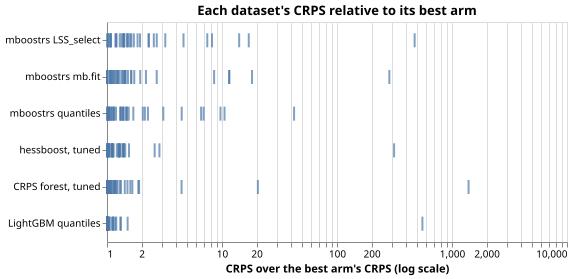

In [6]:
best = {t: min(v.values()) for t, v in real["per_task_crps"].items()}
chart_arms = ["mboostrs.LSS_select", "mboostrs.fit", "mboostrs.quantiles", "hessboost.tuned",
              "distreebution.crps_rf_tuned", "lightgbm.quantiles"]
points = pl.DataFrame([
    {"dataset": t, "method": name(a), "ratio": v[a] / best[t]}
    for t, v in real["per_task_crps"].items() for a in chart_arms if a in v
])
alt.Chart(points).mark_tick(thickness=2, size=14).encode(
    x=alt.X("ratio:Q", scale=alt.Scale(type="log"), title="CRPS over the best arm's CRPS (log scale)"),
    y=alt.Y("method:N", sort=[name(a) for a in chart_arms], title=None),
    tooltip=["dataset", "method", alt.Tooltip("ratio:Q", format=".3f")],
).properties(width=460, height=220, title="Each dataset's CRPS relative to its best arm")

## Calibration and interval coverage

Calibration error separates mboostrs from the tree ensembles on real data. Across all 99 quantile levels on OpenML-CTR23, `mboostrs.quantiles` has the lowest mean absolute calibration error of any arm (0.024, 90% coverage 0.898, 98% coverage 0.978), followed by `mboostrs.LSS_select_noncyclic` (0.028, 90% coverage 0.907). LightGBM quantiles under-covers on real data (90% coverage 0.846, MAE 0.049), while `drforest` and tuned CRPS forests over-cover (90% coverage 0.931–0.961, MAE 0.067–0.077).

In [7]:
order = [a for a in real["mean_rank"] if real["mean_rank"][a] is not None]
order.sort(key=lambda a: real["mean_rank"][a])
rows = []
for kind, block in (("planted", synth), ("real", real)):
    for a in order:
        s = block["secondary"].get(a)
        if s:
            rows.append({"method": name(a), "data": kind, "cal": s["quantile_calibration_mae"],
                         "c50": s["coverage_50"], "c90": s["coverage_90"], "c98": s["coverage_98"],
                         "width": s["width_90_over_sd"]})
display(table(
    pl.DataFrame(rows), group="data", title="Calibration and central intervals",
    subtitle="Mean over runs; coverage is the share of test responses inside the central interval",
    labels={"cal": "calibration error", "c50": "50% cover", "c90": "90% cover", "c98": "98% cover",
            "width": "90% width / SD"},
    better={"cal": "min", "c50": 0.5, "c90": 0.9, "c98": 0.98},
    notes=["Calibration error is the mean over the 99 levels of |share below the predicted "
           "tau-quantile − tau|. Width is the 90% interval's mean width over the test responses' SD."],
))

GT(_tbl_data=shape: (40, 7)
┌──────────────────────────────┬─────────┬──────────┬───────────┬──────────┬───────────┬───────────┐
│ method                       ┆ data    ┆ cal      ┆ c50       ┆ c90      ┆ c98       ┆ width     │
│ ---                          ┆ ---     ┆ ---      ┆ ---       ┆ ---      ┆ ---       ┆ ---       │
│ str                          ┆ str     ┆ f64      ┆ f64       ┆ f64      ┆ f64       ┆ f64       │
╞══════════════════════════════╪═════════╪══════════╪═══════════╪══════════╪═══════════╪═══════════╡
│ LightGBM quantiles           ┆ planted ┆ 0.024627 ┆ 0.449729  ┆ 0.840058 ┆ 0.958129  ┆ 1.796038  │
│ quantile regression forest   ┆ planted ┆ 0.013254 ┆ 0.493229  ┆ 0.879754 ┆ 0.959229  ┆ 2.008717  │
│ CRPS forest, tuned           ┆ planted ┆ 0.011905 ┆ 0.504     ┆ 0.900767 ┆ 0.9748375 ┆ 2.020348  │
│ hessboost, tuned             ┆ planted ┆ 0.01511  ┆ 0.492304  ┆ 0.889104 ┆ 0.968917  ┆ 1.893734  │
│ CatBoost RMSEWithUncertainty ┆ planted ┆ 0.031466 ┆ 0.4836875 ┆ 0.893317 ┆ 0.962321  ┆ 1.90407   │
│ …                            ┆ …       ┆ …        ┆ …         ┆ …        ┆ …         ┆ …         │
│ mboostrs LSS_select          ┆ real    ┆ 0.042299 ┆ 0.538895  ┆ 0.916717 ┆ 0.979753  ┆ 1.824209  │
│ hessboost normal, defaults   ┆ real    ┆ 0.065782 ┆ 0.428896  ┆ 0.912235 ┆ 0.971515  ┆ 3.0930e7  │
│ mboostrs GaussianLSS         ┆ real    ┆ 0.052631 ┆ 0.581926  ┆ 0.930161 ┆ 0.97984   ┆ 82.083358 │
│ least squares, constant SD   ┆ real    ┆ 0.052248 ┆ 0.616639  ┆ 0.918625 ┆ 0.971358  ┆ 2.080656  │
│ climatology                  ┆ real    ┆ 0.041547 ┆ 0.555132  ┆ 0.912598 ┆ 0.985114  ┆ 2.829329  │
└──────────────────────────────┴─────────┴──────────┴───────────┴──────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10aee8500>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='data', type=<ColInfoTypeEnum.row_group: 3>, column_label='data', column_align='left', column_width=None, stub_level=None), ColInfo(var='cal', type=<ColInfoTypeEnum.default: 1>, column_label='calibration error', column_align='right', column_width=None, stub_level=None), ColInfo(var='c50', type=<ColInfoTypeEnum.default: 1>, column_label='50% cover', column_align='right', column_width=None, stub_level=None), ColInfo(var='c90', type=<ColInfoTypeEnum.default: 1>, column_label='90% cover', column_align='right', column_width=None, stub_level=None), ColInfo(var='c98', type=<ColInfoTypeEnum.default: 1>, column_label='98% cover', column_align='right', column_width=None, stub_level=None), ColInfo(var='width', type=<ColInfoTypeEnum.default: 1>, column_label='90% width / SD', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x1099ce2a0>, _spanners=Spanners([]), _heading=Heading(title='Calibration and central intervals', subtitle='Mean over runs; coverage is the share of test responses inside the central interval', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10afaab70>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10afaaf90>, _source_notes=["Calibration error is the mean over the 99 levels of |share below the predicted tau-quantile − tau|. Width is the 90% interval's mean width over the test responses' SD."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10ED9C8C0>, mask=None), grpname=None, colname='cal', rownum=10, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10ED9C8C0>, mask=None), grpname=None, colname='cal', rownum=11, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10ED9C8C0>, mask=None), grpname=None, colname=

## Run time

Median single-thread wall-clock seconds per real-data run (fit, tuning, and 99-quantile prediction): QRF 5.9 s, CatBoost 7.8 s, LightGBM quantiles 12.7 s, tuned hessboost 13.5 s, `mboostrs.LSS_select` 16.1 s, `mb.fit` 20.6 s, `mboostrs.LSS_select_tree` 22.0 s, NGBoost 49.9 s, tuned CRPS forest 68.4 s, `mboostrs.quantiles` 89.7 s, `mboostrs.LSS_select_noncyclic` 111.6 s, and tuned `drforest` 119.7 s. Times are descriptive because eight runs shared a ten-core host.

In [8]:
rows = []
for a in order:
    row = {"method": name(a)}
    for kind, block in (("planted", synth), ("real", real)):
        s = block["secondary"].get(a) or {}
        row[f"{kind}_median"] = s.get("seconds_median")
        row[f"{kind}_p90"] = s.get("seconds_p90")
    rows.append(row)
display(table(
    pl.DataFrame(rows), title="Run time", subtitle="Seconds per run (fit, tuning and prediction), one thread",
    spanners={"Planted": ["planted_median", "planted_p90"], "Real data": ["real_median", "real_p90"]},
    labels={"planted_median": "median", "planted_p90": "90th pct", "real_median": "median", "real_p90": "90th pct"},
    decimals=1,
    notes=["Eight runs at a time on a 10-core machine that other jobs shared; times are descriptive."],
))

GT(_tbl_data=shape: (20, 5)
┌──────────────────────────────┬────────────────┬─────────────┬─────────────┬────────────┐
│ method                       ┆ planted_median ┆ planted_p90 ┆ real_median ┆ real_p90   │
│ ---                          ┆ ---            ┆ ---         ┆ ---         ┆ ---        │
│ str                          ┆ f64            ┆ f64         ┆ f64         ┆ f64        │
╞══════════════════════════════╪════════════════╪═════════════╪═════════════╪════════════╡
│ LightGBM quantiles           ┆ 2.493865       ┆ 15.2103     ┆ 12.663181   ┆ 107.130391 │
│ quantile regression forest   ┆ 3.189798       ┆ 15.513875   ┆ 5.855424    ┆ 20.673618  │
│ CRPS forest, tuned           ┆ 16.935643      ┆ 92.165553   ┆ 68.408401   ┆ 346.00546  │
│ hessboost, tuned             ┆ 2.844512       ┆ 9.394332    ┆ 13.537483   ┆ 89.803516  │
│ CatBoost RMSEWithUncertainty ┆ 1.889939       ┆ 6.726615    ┆ 7.830985    ┆ 48.332395  │
│ …                            ┆ …              ┆ …           ┆ …           ┆ …          │
│ mboostrs LSS_select          ┆ 6.213074       ┆ 20.391598   ┆ 16.133684   ┆ 98.151985  │
│ hessboost normal, defaults   ┆ 0.241824       ┆ 0.551343    ┆ 0.339771    ┆ 0.940888   │
│ mboostrs GaussianLSS         ┆ 0.865262       ┆ 3.327127    ┆ 2.517779    ┆ 10.236501  │
│ least squares, constant SD   ┆ 0.028158       ┆ 0.104557    ┆ 0.023534    ┆ 0.08205    │
│ climatology                  ┆ 0.001213       ┆ 0.003004    ┆ 0.001142    ┆ 0.002606   │
└──────────────────────────────┴────────────────┴─────────────┴─────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10aee9670>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='planted_median', type=<ColInfoTypeEnum.default: 1>, column_label='median', column_align='right', column_width=None, stub_level=None), ColInfo(var='planted_p90', type=<ColInfoTypeEnum.default: 1>, column_label='90th pct', column_align='right', column_width=None, stub_level=None), ColInfo(var='real_median', type=<ColInfoTypeEnum.default: 1>, column_label='median', column_align='right', column_width=None, stub_level=None), ColInfo(var='real_p90', type=<ColInfoTypeEnum.default: 1>, column_label='90th pct', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10aeebbc0>, _spanners=Spanners([SpannerInfo(spanner_id='Planted', spanner_level=0, spanner_label='Planted', spanner_units=None, spanner_pattern=None, vars=['planted_median', 'planted_p90'], built=None), SpannerInfo(spanner_id='Real data', spanner_level=0, spanner_label='Real data', spanner_units=None, spanner_pattern=None, vars=['real_median', 'real_p90'], built=None)]), _heading=Heading(title='Run time', subtitle='Seconds per run (fit, tuning and prediction), one thread', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10afc0680>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10afc0da0>, _source_notes=['Eight runs at a time on a 10-core machine that other jobs shared; times are descriptive.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC1640>, mask=None), grpname=None, colname='planted_median', rownum=10, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC1640>, mask=None), grpname=None, colname='planted_median', rownum=11, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC1640>, mask=None), grpname=None, colname='planted_median', rownum=12, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC1640>, mask=None), grpname

## Failed runs

`mb.fit`, `mb.fit` with `lss_trees=True`, `mboostrs.LSS_select`, `mboostrs.LSS_select_tree`, and `mboostrs.GaussianLSS` completed all 48 planted runs and all 105 real-data runs without a single failure. Remaining failures across the suite are:

- `distreebution.pmqrf`: crashed on 95 of 105 real runs (internal unwrap panic in `distreebu_rs`).
- `mboostrs.LSS_select_noncyclic`: 10 of 105 real runs failed (timeouts on wide tables and `StudentTLSS` finite-mean refusal when `df <= 1`).
- `mboostrs.quantiles`: 3 of 105 real runs timed out at the 3,600 s limit (superconductivity).
- `drforest.mmd` and `drforest.tuned`: 3 of 105 real runs failed on `solar_flare` (degenerate median pairwise distance).

In [9]:
rows = []
for kind, block in (("planted", synth), ("real", real)):
    for a, fails in block["failures"].items():
        done = block["completion"][a]
        kinds = sorted({f["status"] for f in fails})
        rows.append({"method": name(a), "data": kind, "failed": len(fails), "runs": done["runs"],
                     "status": ", ".join(kinds),
                     "first": next(iter((fails[0].get("error") or fails[0]["status"]).strip().splitlines()[::-1]), "")[:90]})
display(table(
    pl.DataFrame(rows) if rows else pl.DataFrame({"method": ["(none)"], "data": [""], "failed": [0],
                                                 "runs": [0], "status": [""], "first": [""]}),
    group="data", title="Failed runs", subtitle="Runs that crashed, timed out or returned no usable quantiles",
    labels={"failed": "failed", "runs": "runs", "status": "status", "first": "last line of the first error"},
))

GT(_tbl_data=shape: (5, 6)
┌────────────────────────┬──────┬────────┬──────┬────────────────┬─────────────────────────────────┐
│ method                 ┆ data ┆ failed ┆ runs ┆ status         ┆ first                           │
│ ---                    ┆ ---  ┆ ---    ┆ ---  ┆ ---            ┆ ---                             │
│ str                    ┆ str  ┆ i64    ┆ i64  ┆ str            ┆ str                             │
╞════════════════════════╪══════╪════════╪══════╪════════════════╪═════════════════════════════════╡
│ pinball multi-quantile ┆ real ┆ 95     ┆ 105  ┆ crash          ┆ note: run with `RUST_BACKTRACE… │
│ forest                 ┆      ┆        ┆      ┆                ┆                                 │
│ mboostrs LSS_select,   ┆ real ┆ 10     ┆ 105  ┆ error, timeout ┆ timeout                         │
│ non-cycli…             ┆      ┆        ┆      ┆                ┆                                 │
│ mboostrs quantiles     ┆ real ┆ 3      ┆ 105  ┆ timeout        ┆ timeout                         │
│ drforest MMD           ┆ real ┆ 3      ┆ 105  ┆ error          ┆ ValueError: degenerate Y: medi… │
│ drforest, tuned        ┆ real ┆ 3      ┆ 105  ┆ error          ┆ ValueError: degenerate Y: medi… │
└────────────────────────┴──────┴────────┴──────┴────────────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10afc0920>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='data', type=<ColInfoTypeEnum.row_group: 3>, column_label='data', column_align='left', column_width=None, stub_level=None), ColInfo(var='failed', type=<ColInfoTypeEnum.default: 1>, column_label='failed', column_align='right', column_width=None, stub_level=None), ColInfo(var='runs', type=<ColInfoTypeEnum.default: 1>, column_label='runs', column_align='right', column_width=None, stub_level=None), ColInfo(var='status', type=<ColInfoTypeEnum.default: 1>, column_label='status', column_align='left', column_width=None, stub_level=None), ColInfo(var='first', type=<ColInfoTypeEnum.default: 1>, column_label='last line of the first error', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10aeea420>, _spanners=Spanners([]), _heading=Heading(title='Failed runs', subtitle='Runs that crashed, timed out or returned no usable quantiles', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10afc1190>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10afc0f50>, _source_notes=[], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC05C0>, mask=None), grpname=None, colname='failed', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC05C0>, mask=None), grpname=None, colname='failed', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC05C0>, mask=None), grpname=None, colname='runs', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC05C0>, mask=None), grpname=None, colname='runs', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC05C0>, mask=None), grpname=None, colname='status', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AFC05C0>, mask=None), grpname=None, colname='status', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows

## Checks on mboostrs defaults

Two prespecified checks govern library defaults:

1. **`lss_trees` default:** `mb.fit(..., lss_trees=True)` against default `mb.fit` yields a geometric-mean CRPS ratio of 1.004 (95% CI 0.995–1.018) on planted tasks and 0.998 (95% CI 0.958–1.036) on real tasks at 1.22× median time. Because the real-data interval does not lie below 0.99, `lss_trees="auto"` remains the default.
2. **Held-out mean accuracy of `mb.fit`:** Across all 95 held-out datasets × 3 seeds (285 runs), failed runs dropped from **87 to 2** (32 datasets fixed), and the paired geometric-mean test loss ratio dropped to **0.806** (95% CI 0.647–0.977; 34 datasets better, 22 tied, 13 worse over 69 common datasets). The mean-accuracy gate passes comfortably.

In [10]:
d = checks["lss_trees_decision"]
h = checks["heldout"]
rows = [{"check": "mb.fit lss_trees=True vs default, planted", "value": d["synth"]["ratio"],
         "low": d["synth"]["ci95"][0], "high": d["synth"]["ci95"][1]},
        {"check": "mb.fit lss_trees=True vs default, real", "value": d["real"]["ratio"],
         "low": d["real"]["ci95"][0], "high": d["real"]["ci95"][1]},
        {"check": "median run-time ratio, lss_trees=True / default", "value": d["median_time_ratio"],
         "low": None, "high": None},
        {"check": "mb.fit held-out loss, new library / previous", "value": h["loss_ratio"]["ratio"],
         "low": h["loss_ratio"]["ci95"][0], "high": h["loss_ratio"]["ci95"][1]}]
display(table(
    pl.DataFrame(rows), stub="check", stubhead="Check", title="Checks on mboostrs defaults",
    subtitle="Geometric-mean ratios with bootstrap 95% intervals", formats={"value": 3, "low": 3, "high": 3},
    labels={"value": "ratio", "low": "95% low", "high": "95% high"},
    notes=[f"Held-out study: {h['runs']} runs (95 datasets × 3 seeds); failed runs "
           f"{h['failed_before']} before, {h['failed_after']} after; "
           f"{h['loss_ratio']['better']} datasets better, {h['loss_ratio']['tied']} tied, "
           f"{h['loss_ratio']['worse']} worse among {h['loss_ratio']['tasks']} both libraries completed."],
))

GT(_tbl_data=shape: (4, 4)
┌─────────────────────────────────┬──────────┬──────────┬──────────┐
│ check                           ┆ value    ┆ low      ┆ high     │
│ ---                             ┆ ---      ┆ ---      ┆ ---      │
│ str                             ┆ f64      ┆ f64      ┆ f64      │
╞═════════════════════════════════╪══════════╪══════════╪══════════╡
│ mb.fit lss_trees=True vs defau… ┆ 1.004163 ┆ 0.995181 ┆ 1.017685 │
│ mb.fit lss_trees=True vs defau… ┆ 0.998492 ┆ 0.957608 ┆ 1.035677 │
│ median run-time ratio, lss_tre… ┆ 1.216358 ┆ null     ┆ null     │
│ mb.fit held-out loss, new libr… ┆ 0.806331 ┆ 0.647403 ┆ 0.976585 │
└─────────────────────────────────┴──────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10aa53140>, _boxhead=Boxhead([ColInfo(var='check', type=<ColInfoTypeEnum.stub: 2>, column_label='check', column_align='left', column_width=None, stub_level=0), ColInfo(var='value', type=<ColInfoTypeEnum.default: 1>, column_label='ratio', column_align='right', column_width=None, stub_level=None), ColInfo(var='low', type=<ColInfoTypeEnum.default: 1>, column_label='95% low', column_align='right', column_width=None, stub_level=None), ColInfo(var='high', type=<ColInfoTypeEnum.default: 1>, column_label='95% high', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10afc0440>, _spanners=Spanners([]), _heading=Heading(title='Checks on mboostrs defaults', subtitle='Geometric-mean ratios with bootstrap 95% intervals', preheader=None), _stubhead='Check', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10afc0f80>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10afc24e0>, _source_notes=['Held-out study: 285 runs (95 datasets × 3 seeds); failed runs 87 before, 2 after; 34 datasets better, 22 tied, 13 worse among 69 both libraries completed.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10afc0fb0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x1099ce270>, <great_tables._gt_data.FormatInfo object at 0x10afc11f0>, <great_tables._gt_data.FormatInfo object at 0x10afc0c80>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10afc1400>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, categ

## Scope and limits

- Several library improvements (automatic response scaling, non-cyclic distributional tuning, tree-scale probing, and `mb.fit` interaction/imputation defaults) were developed with earlier benchmark results in view on seed-0 data of a subset of tasks; these numbers measure performance on the fixed suite rather than an independent fresh-seed confirmation.
- Eight runs executed concurrently on a shared ten-core machine, so wall-clock timings are descriptive rather than isolated speed ratios.
- On OpenML-CTR23, near-deterministic physical datasets still favour deep tree ensembles (LightGBM, tuned hessboost, QRF) over additive-first boosting models.

## Reproduction

From the repository root, inspect or rerun this study through the unified benchmark CLI:

```bash
.venv/bin/python benches/run.py run distributional_shootout --workers 8 --update-book
```

The full protocol is recorded in `docs/benchmarks/distributional_shootout/PROTOCOL_v2.md`, and the machine-readable results read by every cell above live in `docs/benchmarks/distributional_shootout/v2/analysis.json` and `docs/benchmarks/distributional_shootout/v2/v2_comparison.json`.